# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** Игнатенко Анастасия

**Период данных:** 2024-01-01 — 2025-06-30

**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

clean = pd.read_parquet('clean_data.parquet')
txn = pd.read_parquet('clean_transactions.parquet')
campaign = pd.read_csv('campaign_list.csv')
log = pd.read_csv('cleaning_log.csv')
excl = pd.read_csv('exclusions.csv').set_index('кто')['клиентов']

## 1. Главное

1. **Активность упала не у всех, а у трети клиентов.** У 1521 из 4839 клиентов (31%) операций в январе–июне 2025 года стало меньше ожидаемого на 40% и больше, у остальных уровень почти обычный.
2. **Главная причина — клиенты перестали платить картой и ничем её не заменили.** Так сделали 68% клиентов с сильным падением.
3. **Чаще всего это массовые клиенты без приложения**: 44% против 26% у массовых с приложением.
4. **Отдельная причина — развлечения**: в январе–июне 2025 года по ним было 62% операций от среднего за 2024 год, по остальным категориям 77–82%.
5. **Для кампании предлагаем 4 группы, всего 1241 клиент с согласием на коммуникацию**: перестали тратить на развлечения (365), массовые без приложения (372), массовые с приложением (351), зарплатные и премиальные с уровнем Базовый или Серебро (153).

## 2. Контекст

За последние полгода клиенты банка стали реже пользоваться картами. Департамент розничных продуктов готовит кампанию по возврату активности и должен решить, к кому с ней идти. Бюджет кампании — не больше 2000 клиентов. Нужно от 3 до 5 групп, в каждой не меньше 150 человек. По каждой группе нужно понимать, за счёт чего упала активность, иначе непонятно, что этим людям предложить. Писать можно только клиентам с согласием на коммуникацию.

## 3. Данные и ограничения

**Данные.** Справочник клиентов на 30.06.2025 и операции по картам с 01.01.2024 по 30.06.2025. Базовый период — 2024 год, оцениваемый — январь–июнь 2025 года.

**Что исключено.** Клиенты, которых нет в справочнике; клиенты, открывшие карту в 2024–2025 годах; клиенты, у которых в 2024 году меньше одной успешной операции в месяц. При очистке удалены дубли, операции с ненадёжными датами и код отделения.

**Чего в данных нет.**
- Причин, по которым клиенты стали реже пользоваться картой: обращений в банк, жалоб.
- Истории изменений признаков клиента. Сегмент, уровень лояльности и наличие приложения известны только на 30.06.2025.
- Состояния карты и истории её перевыпусков: истёк ли срок, была ли карта заблокирована или потеряна.
- Больше одного года до периода оценки. Сезонность оценена только по 2024 году.

**Метрика.** Активность клиента — число его успешных операций в месяц по всем способам оплаты. Сравниваем январь–июнь 2025 года с уровнем клиента в 2024 году с поправкой на сезон: январь–июнь всегда спокойнее года в целом (коэффициент 0.931), поэтому ожидаемый уровень — это уровень 2024 года, умноженный на 0.931. Метрика не заметит, если клиент стал тратить меньше при том же числе операций, перенёс траты из одной категории в другую или перестал платить только в июне

In [17]:
# Данные и ограничения: числа для раздела 3
ok = txn[txn['status'] == 'успешно']
per_m = ok.groupby(ok['txn_datetime'].dt.to_period('M')).size()
SEASON_H1 = per_m['2024-01':'2024-06'].mean() / per_m['2024-01':'2024-12'].mean()

print(f'Период: {txn["txn_datetime"].min():%d.%m.%Y} — {txn["txn_datetime"].max():%d.%m.%Y}')
print(f'Клиентов в анализе: {len(clean)}, успешных операций у них: {len(ok)}')

Период: 01.01.2024 — 30.06.2025
Клиентов в анализе: 4839, успешных операций у них: 557311


## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

In [18]:
# Оформление графиков: цвета и подпись-источник
BLUE, RED, GRAY = '#4C72B0', '#C44E52', '#9E9E9E'

### 4.1. Активность упала не у всех клиентов, а примерно у трети

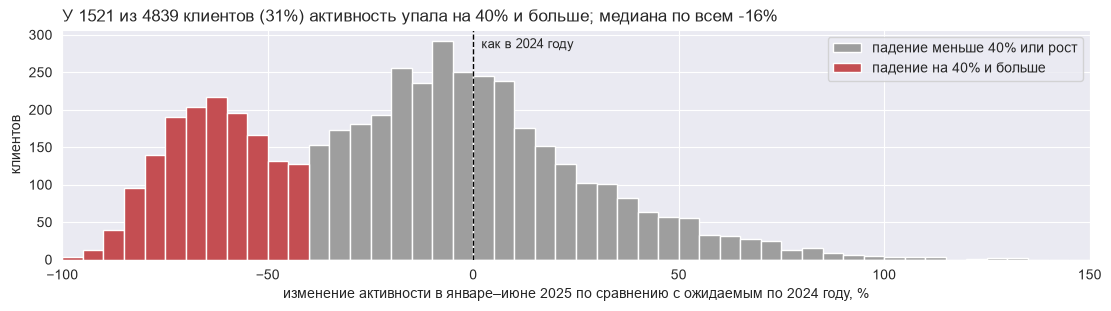

In [19]:
# Распределение изменения активности
strong = clean['activity_change'] <= -40
median_change = clean['activity_change'].median()

fig, ax = plt.subplots(figsize=(11, 3.0), layout='constrained')
ax.hist(clean.loc[~strong, 'activity_change'], bins=np.arange(-100, 200, 5), color=GRAY, label='падение меньше 40% или рост')
ax.hist(clean.loc[strong, 'activity_change'], bins=np.arange(-100, 200, 5), color=RED, label='падение на 40% и больше')
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.text(1, ax.get_ylim()[1] * 0.92, ' как в 2024 году', fontsize=9)
ax.set_xlim(-100, 150)
ax.set_title(f'У {strong.sum()} из {len(clean)} клиентов ({strong.mean():.0%}) активность упала на 40% и больше; '
             f'медиана по всем {median_change:.0f}%', loc='left')
ax.set_xlabel('изменение активности в январе–июне 2025 по сравнению с ожидаемым по 2024 году, %')
ax.set_ylabel('клиентов')
ax.legend(loc='upper right')
plt.show()

Если бы активность снижалась у всех понемногу, на графике был бы один горб, просто сдвинутый влево. Вместо этого горбов два: у большинства клиентов активность осталась близкой к обычной, а около трети клиентов образуют отдельную группу, у которой активность упала в разы. Это не общий спад, а две разные группы клиентов: у одной ничего особенного не произошло, у другой что-то изменилось, и они стали платить в разы реже.

### 4.2. Главная причина падения — клиенты перестали платить картой и не перешли на другой способ оплаты

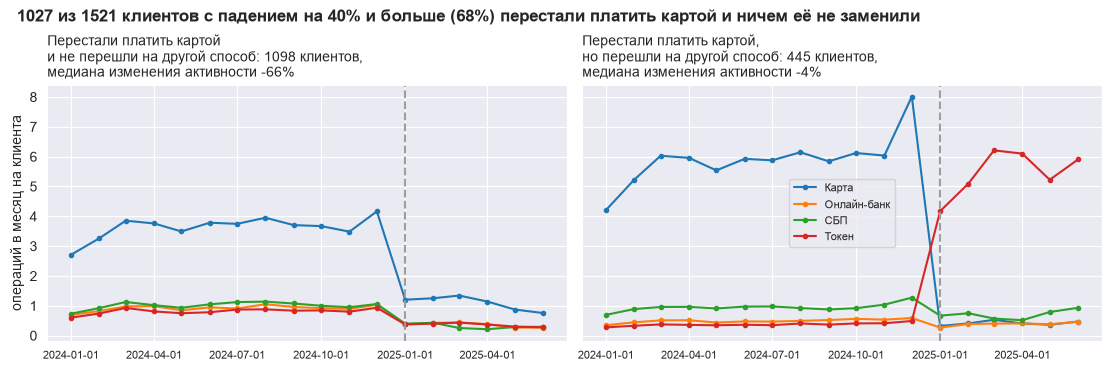

In [20]:
# Кто перестал платить картой и кто из них перешёл на другой способ (правила как в рабочем ноутбуке)
is_2024 = ok['txn_datetime'] < '2025-01-01'
is_card = ok['channel'] == 'Карта'

def per_month(mask, months):
    return clean['client_id'].map(ok[mask].groupby('client_id').size() / months).fillna(0)

card_2024, card_2025 = per_month(is_2024 & is_card, 12), per_month(~is_2024 & is_card, 6)
other_2024, other_2025 = per_month(is_2024 & ~is_card, 12), per_month(~is_2024 & ~is_card, 6)
card_expected = card_2024 * SEASON_H1
card_dropped = (card_2024 >= 1) & (card_2025 <= card_expected * 0.5)
switched = card_dropped & (other_2025 - other_2024 * SEASON_H1 >= (card_expected - card_2025) * 0.5)
lost_card = card_dropped & ~switched

# Операции по каналам по месяцам у двух групп, графики рядом
month = ok['txn_datetime'].dt.to_period('M')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout='constrained')
for ax, (name, mask) in zip(axes, [('Перестали платить картой\nи не перешли на другой способ', lost_card),
                                   ('Перестали платить картой,\nно перешли на другой способ', switched)]):
    ops = ok[ok['client_id'].isin(clean.loc[mask, 'client_id'])]
    by_channel = ops.groupby([month[ops.index], 'channel'], observed=True).size().unstack(fill_value=0) / mask.sum()
    for ch in by_channel.columns:
        ax.plot(by_channel.index.to_timestamp(), by_channel[ch], marker='o', markersize=3, label=ch)
    ax.axvline(pd.Timestamp('2025-01-01'), color=GRAY, linestyle='--')
    med = clean.loc[mask, 'activity_change'].median()
    ax.set_title(f'{name}: {mask.sum()} клиентов,\nмедиана изменения активности {med:.0f}%', loc='left', fontsize=10)
    # Подписи только у начала каждого квартала, иначе даты налезают друг на друга
    ax.set_xticks(pd.date_range('2024-01-01', '2025-04-01', freq='QS'))
    ax.tick_params(axis='x', labelsize=8)
axes[0].set_ylabel('операций в месяц на клиента')
axes[1].legend(fontsize=8)

both = strong & lost_card
fig.suptitle(f'{both.sum()} из {strong.sum()} клиентов с падением на 40% и больше ({both.sum() / strong.sum():.0%}) '
             f'перестали платить картой и ничем её не заменили', x=0.01, ha='left', fontweight='bold')
plt.show()

У клиентов на верхнем графике с января 2025 года резко упала оплата картой, а другие способы оплаты не выросли: операции просто пропали. Это две трети всех клиентов с сильным падением активности. Клиенты на нижнем графике тоже почти перестали платить картой, но перешли на оплату телефоном и СБП, поэтому их общая активность почти не изменилась. Значит, сам по себе отказ от карты не проблема. Проблема возникает, когда клиенту нечем её заменить.

### 4.3. Чаще всего карту бросают массовые клиенты без мобильного приложения

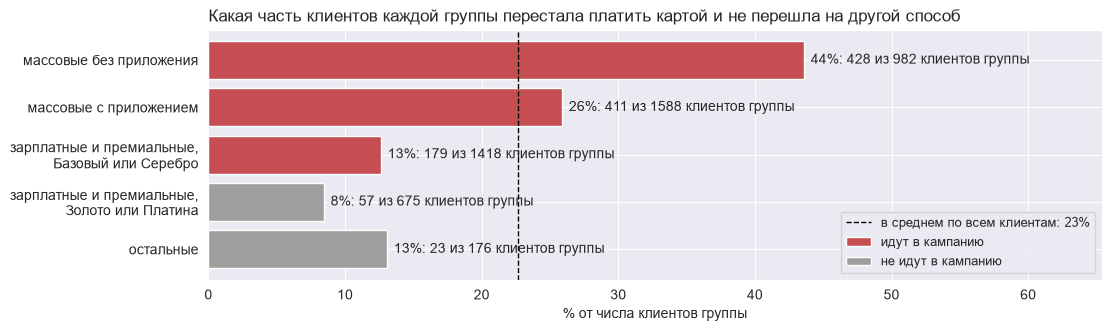

In [21]:
# Доля переставших платить картой и не перешедших, по группам клиентов
mass = clean['segment'] == 'Массовый'
app = clean['has_mobile_app']
sal_prem = clean['segment'].isin(['Зарплатный', 'Премиальный'])
low_tier = clean['loyalty_tier'].isin(['Базовый', 'Серебро'])

who = pd.Series('остальные', index=clean.index)
who[sal_prem & ~low_tier] = 'зарплатные и премиальные,\nЗолото или Платина'
who[sal_prem & low_tier] = 'зарплатные и премиальные,\nБазовый или Серебро'
who[mass & app] = 'массовые с приложением'
who[mass & ~app] = 'массовые без приложения'
order = ['массовые без приложения', 'массовые с приложением',
         'зарплатные и премиальные,\nБазовый или Серебро',
         'зарплатные и премиальные,\nЗолото или Платина', 'остальные']

stat = lost_card.groupby(who).agg(['mean', 'sum', 'size']).reindex(order)
in_campaign, not_in_campaign = order[:3], order[3:]

fig, ax = plt.subplots(figsize=(11, 3.2), layout='constrained')
ax.barh(in_campaign, stat.loc[in_campaign, 'mean'] * 100, color=RED, label='идут в кампанию')
ax.barh(not_in_campaign, stat.loc[not_in_campaign, 'mean'] * 100, color=GRAY, label='не идут в кампанию')
for i, (share, k, n) in enumerate(stat.itertuples(index=False)):
    ax.text(share * 100 + 0.5, i, f'{share:.0%}: {k} из {n} клиентов группы', va='center', fontsize=10)
ax.axvline(lost_card.mean() * 100, color='black', linestyle='--', linewidth=1,
           label=f'в среднем по всем клиентам: {lost_card.mean():.0%}')
ax.invert_yaxis()
ax.set_xlim(0, stat['mean'].max() * 100 * 1.5)
ax.set_xlabel('% от числа клиентов группы')
ax.legend(loc='lower right', fontsize=9)
ax.set_title('Какая часть клиентов каждой группы перестала платить картой и не перешла на другой способ', loc='left')
plt.show()

Чаще всего перестают платить картой массовые клиенты без приложения, почти вдвое чаще, чем с приложением. Вероятно, у них нет удобной замены карте: без приложения не оплатишь телефоном и не переведёшь через СБП, поэтому, перестав платить картой, они перестают платить через банк вовсе. Среди зарплатных и премиальных клиентов это происходит реже среднего, но на уровнях Базовый и Серебро заметно чаще, чем на Золоте и Платине. Это ценные для банка клиенты, поэтому их стоит вернуть отдельной коммуникацией.

### 4.4. Развлечения упали сильнее всех остальных категорий трат

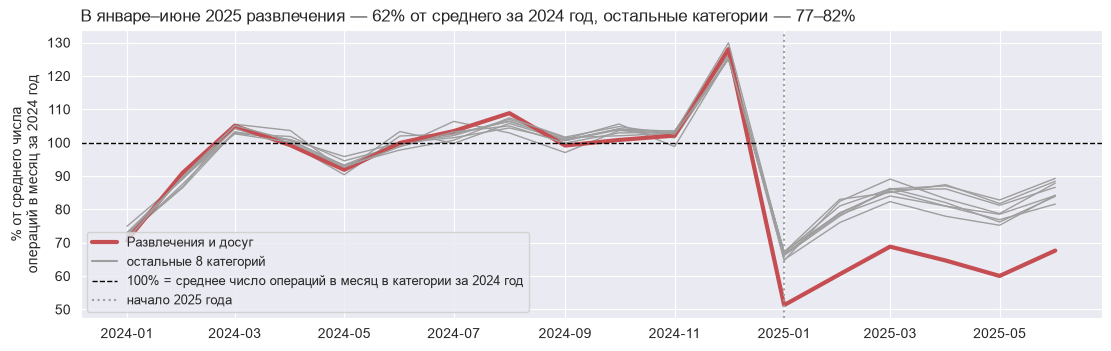

In [22]:
# Операции по категориям по месяцам относительно среднего за 2024 год, все клиенты
month = ok['txn_datetime'].dt.to_period('M')
by_cat = ok.groupby([month, 'category'], observed=True).size().unstack()
by_cat = by_cat / by_cat.loc['2024-01':'2024-12'].mean() * 100
level_2025 = by_cat.loc['2025-01':'2025-06'].mean()
others = level_2025.drop('Развлечения и досуг')

fig, ax = plt.subplots(figsize=(11, 3.4), layout='constrained')
for cat in by_cat.columns:
    is_ent = cat == 'Развлечения и досуг'
    ax.plot(by_cat.index.to_timestamp(), by_cat[cat], color=RED if is_ent else GRAY,
            linewidth=3 if is_ent else 1, label='Развлечения и досуг' if is_ent else None)
ax.plot([], [], color=GRAY, label='остальные 8 категорий')
ax.axhline(100, color='black', linestyle='--', linewidth=1,
           label='100% = среднее число операций в месяц в категории за 2024 год')
ax.axvline(pd.Timestamp('2025-01-01'), color=GRAY, linestyle=':', label='начало 2025 года')
ax.set_title(f'В январе–июне 2025 развлечения — {level_2025["Развлечения и досуг"]:.0f}% от среднего за 2024 год, '
             f'остальные категории — {others.min():.0f}–{others.max():.0f}%', loc='left')
ax.set_ylabel('% от среднего числа\nопераций в месяц за 2024 год')
ax.legend(fontsize=9, loc='lower left')
plt.show()

До 2025 года все категории трат менялись одинаково, с общей сезонностью и пиком в декабре. В 2025 году число операций снизилось во всех категориях, но в развлечениях заметно сильнее, чем в любой другой. Значит, кроме общего снижения есть отдельная причина, связанная именно с развлечениями. Её затронула часть клиентов: в группу вошли те, у кого развлечения были заметной частью трат и сократились минимум вдвое, а остальные операции почти не изменились.

## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->

In [23]:
# Группы для кампании: правило отбора, размер, причина падения
clean['group'] = clean['client_id'].map(campaign.set_index('client_id')['group'])
groups_info = {
    'перестали тратить на развлечения': (
        'в 2024 развлечения ≥ 12% операций; в 2025 их вдвое меньше ожидаемого, остальные операции ≥ 80% ожидаемого',
        'перестали тратить на развлечения, остальные траты не изменились'),
    'массовые без приложения, перестали платить картой': (
        'массовый сегмент, нет приложения; оплата картой вдвое ниже ожидаемой, другие способы не выросли',
        'перестали платить картой, замены нет: без приложения не оплатить телефоном и не перевести через СБП'),
    'массовые с приложением, перестали платить картой': (
        'массовый сегмент, есть приложение; оплата картой вдвое ниже ожидаемой, другие способы не выросли',
        'перестали платить картой и не перешли на оплату телефоном или СБП, хотя приложение есть'),
    'зарплатные и премиальные с Базовым или Серебром, перестали платить картой': (
        'зарплатный или премиальный сегмент, уровень Базовый или Серебро; оплата картой вдвое ниже ожидаемой, '
        'другие способы не выросли',
        'перестали платить картой и не перешли на другой способ'),
}
rows = []
for name, (rule, cause) in groups_info.items():
    g = clean[clean['group'] == name]
    rows.append({
        'Группа': name,
        'Правило отбора': rule,
        'Размер': len(g),
        'Изменение активности (медиана)': f'{g["activity_change"].median():.0f}%',
    })
display(pd.DataFrame(rows).style.hide(axis='index'))
print(f'Всего в кампании: {len(campaign)} клиентов, все с согласием на коммуникацию')

Группа,Правило отбора,Размер,Изменение активности (медиана)
перестали тратить на развлечения,"в 2024 развлечения ≥ 12% операций; в 2025 их вдвое меньше ожидаемого, остальные операции ≥ 80% ожидаемого",365,-18%
"массовые без приложения, перестали платить картой","массовый сегмент, нет приложения; оплата картой вдвое ниже ожидаемой, другие способы не выросли",372,-69%
"массовые с приложением, перестали платить картой","массовый сегмент, есть приложение; оплата картой вдвое ниже ожидаемой, другие способы не выросли",351,-65%
"зарплатные и премиальные с Базовым или Серебром, перестали платить картой","зарплатный или премиальный сегмент, уровень Базовый или Серебро; оплата картой вдвое ниже ожидаемой, другие способы не выросли",153,-63%


Всего в кампании: 1241 клиентов, все с согласием на коммуникацию


**Перестали тратить на развлечения.** У этих клиентов развлечения были заметной частью трат, а в 2025 году почти пропали, при этом остальные операции не изменились. Они продолжают пользоваться картой, но перестали тратить на развлечения: возможно, их привлекли предложения конкурентов в этой категории.

**Массовые клиенты без приложения, перестали платить картой.** Перестали платить картой и ничем её не заменили, их активность упала сильнее всех. Без приложения у них нет удобной замены карте.

**Массовые клиенты с приложением, перестали платить картой.** То же самое, но приложение у них есть.

**Зарплатные и премиальные клиенты с уровнем Базовый или Серебро, перестали платить картой.** Это ценные для банка клиенты: зарплата часто приходит в банк. Карту они перестают использовать реже, чем массовые, но чаще, чем клиенты с высоким уровнем лояльности.

**Пересечение причин.** Если клиент подходит под несколько групп, он попадает в первую по списку.

## 6. Кого не включаем и почему

<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->

In [24]:
# Кого не включаем в кампанию и почему
rows = [
    ('нет в справочнике', 'Нет в справочнике', 'скорее всего, ушли из банка, связаться нельзя'),
    ('карта открыта в 2024–2025', 'Карта открыта в 2024–2025', 'нет полного 2024 года для сравнения'),
    ('нет операций или меньше одной в месяц в 2024', 'Меньше 1 операции в месяц в 2024', 'новые и неактивные клиенты, падение с такой базы не посчитать'),
    ('перешли на другой способ оплаты', 'Перешли на телефон или СБП', 'активность не упала'),
    ('бросили карту, но не попали в группы', 'Бросили карту, Золото, Платина, Private', 'их мало, лучше личная работа менеджера'),
    ('падение без видимой причины', 'Падение без видимой причины', 'непонятно, что предложить'),
    ('подходят под группу, но нет согласия', 'Подходят, но нет согласия', 'писать без согласия нельзя'),
]
excluded = pd.DataFrame({
    'Кто': [label for _, label, _ in rows],
    'Клиентов': [excl[key] for key, _, _ in rows],
    'Почему не включаем': [reason for _, _, reason in rows],
})
display(excluded.style.hide(axis='index'))

Кто,Клиентов,Почему не включаем
Нет в справочнике,375,"скорее всего, ушли из банка, связаться нельзя"
Карта открыта в 2024–2025,773,нет полного 2024 года для сравнения
Меньше 1 операции в месяц в 2024,13,"новые и неактивные клиенты, падение с такой базы не посчитать"
Перешли на телефон или СБП,445,активность не упала
"Бросили карту, Золото, Платина, Private",76,"их мало, лучше личная работа менеджера"
Падение без видимой причины,552,"непонятно, что предложить"
"Подходят, но нет согласия",186,писать без согласия нельзя


## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->

In [25]:
# Что проверили и что не подтвердилось
other_bank = clean['income_source'] == 'Зарплата в другом банке'
ekb = clean['city'] == 'Екатеринбург'

def share(mask):
    return strong[mask].mean()

# 1. Падение временное: кто сильно просел в январе–марте, вернулся ли к апрелю–июню
per_m24 = ok[is_2024].groupby(ok.loc[is_2024, 'txn_datetime'].dt.to_period('M')).size()
s_q1 = per_m24['2024-01':'2024-03'].mean() / per_m24.mean()
s_q2 = per_m24['2024-04':'2024-06'].mean() / per_m24.mean()
in_q1 = (ok['txn_datetime'] >= '2025-01-01') & (ok['txn_datetime'] < '2025-04-01')
in_q2 = ok['txn_datetime'] >= '2025-04-01'
r_q1 = per_month(in_q1, 3) / (clean['ops_per_month_2024'] * s_q1)
r_q2 = per_month(in_q2, 3) / (clean['ops_per_month_2024'] * s_q2)
low_q1 = r_q1 <= 0.5

hypotheses = pd.DataFrame([
    ('Падение временное: клиенты просели в начале года и вернулись',
     f'из {low_q1.sum()} клиентов, у которых в январе–марте было не больше половины ожидаемых операций, '
     f'к апрелю–июню вернулись хотя бы к 90% только {(low_q1 & (r_q2 >= 0.9)).sum()}'),
    ('Клиенты ушли к конкуренту: зарплата приходит в другой банк',
     f'среди массовых клиентов активность упала на 40% и больше у {share(other_bank & mass):.0%} '
     f'с зарплатой в другом банке и у {share(~other_bank & mass):.0%} остальных'),
    ('Чаще падает активность клиентов из Екатеринбурга',
     f'по всем клиентам {share(ekb):.0%} против {share(~ekb):.0%}, но среди массовых '
     f'{share(ekb & mass):.0%} против {share(~ekb & mass):.0%}: в Екатеринбурге просто больше массовых клиентов'),
], columns=['Гипотеза', 'Что показали данные'])
display(hypotheses.style.hide(axis='index'))

Гипотеза,Что показали данные
Падение временное: клиенты просели в начале года и вернулись,"из 1096 клиентов, у которых в январе–марте было не больше половины ожидаемых операций, к апрелю–июню вернулись хотя бы к 90% только 71"
Клиенты ушли к конкуренту: зарплата приходит в другой банк,среди массовых клиентов активность упала на 40% и больше у 48% с зарплатой в другом банке и у 44% остальных
Чаще падает активность клиентов из Екатеринбурга,"по всем клиентам 42% против 29%, но среди массовых 47% против 45%: в Екатеринбурге просто больше массовых клиентов"


## 8. Приложение

### 8.1. Сводка журнала изменений

<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->

In [26]:
# Сводка журнала изменений: главные решения
key_issues = ['одна операция записана дважды', 'блок номеров', 'один город записан',
              'одна категория записана', 'метка -999', 'доход записан в тысячах']
summary_log = log[log['issue'].apply(lambda s: any(k in s for k in key_issues))]
summary_log = summary_log[['field', 'issue', 'n_rows', 'action']].rename(columns={
    'field': 'Поле', 'issue': 'Что найдено', 'n_rows': 'Строк', 'action': 'Что сделано'})
display(summary_log.style.hide(axis='index'))
print(f'Полный журнал ({len(log)} записей) — в файле cleaning_log.csv')

Поле,Что найдено,Строк,Что сделано
txn_datetime,"одна операция записана дважды, с временем и без",228,удалено
city,один город записан разными способами,1604,исправлено
category,одна категория записана разными способами,51337,исправлено
monthly_income,метка -999 вместо дохода,52,исправлено
monthly_income,доход записан в тысячах рублей,180,исправлено
все поля,"блок номеров отдельно от основной нумерации, даты не согласованы с номерами",220,удалено


Полный журнал (32 записей) — в файле cleaning_log.csv


### 8.2. Методика

**Данные.** В анализе клиенты из справочника на 30.06.2025 с картой, открытой до 2024 года, и хотя бы одной успешной операцией в месяц в 2024 году. Активность считается только по успешным операциям.

**Метрика.** Активность — число успешных операций клиента в месяц по всем способам оплаты. Изменение активности = операций в месяц в январе–июне 2025 / (операций в месяц в 2024 × 0.931) − 1, где 0.931 — отношение среднего числа операций в январе–июне 2024 к среднему за весь 2024 год. Сильное падение — изменение −40% и ниже: здесь проходит провал между двумя горбами распределения.

**Перестал платить картой** — в 2024 году платил картой не реже раза в месяц, а в 2025 году картой не больше половины ожидаемого. **Перешёл на другой способ** — операции другими способами выросли хотя бы на половину потерянных операций картой, иначе клиент перестал платить картой и не перешёл.

**Перестал тратить на развлечения** — в 2024 году развлечения составляли не меньше 12% операций (20% клиентов с самой большой долей), в 2025 году их не больше половины ожидаемого, а остальные операции не меньше 80% ожидаемого (не хуже медианы по всем клиентам, −16%). При пересечении с другими группами клиент попадает в развлечения, остальные группы не пересекаются.

### 8.3. Использование ИИ

ИИ-ассистент помогал мне с написанием кода, объяснял непонятные места и подсказывал формулировки для текста и журнала изменений. Что чистить, какую метрику взять, какие графики смотреть и как выделить группы, решала я сама и все предложения ассистента оценивала критически и проверяла на данных, прежде чем принять.